In [8]:
from collections import Counter
import pandas as pd
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


data = pd.read_excel(r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage5_deybe\296×87.xlsx")
X = data.iloc[:, 3:]
X
feature_names = X.columns
X = StandardScaler().fit_transform(X)

min_val = np.min(X, axis=0)
max_val = np.max(X, axis=0)
X = (X - min_val) / (max_val - min_val)
imputer = SimpleImputer(strategy="mean")
X = imputer.fit_transform(X)
X.shape

(296, 87)

In [9]:

def extract_numbers(file_path):
    df = pd.read_excel(file_path)
    valid_numbers = []
    for index, value in df['composition'].items():
        if not pd.isna(value):
            valid_numbers.append(int(df.at[index, 'number']))
    return valid_numbers

file_path = r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage5_deybe\benchmark5.xlsx"
reported_structures = extract_numbers(file_path)
print(reported_structures)


def remove_noise_by_nearest_cluster(X, labels):
    """"""

    noise_mask = labels == -1


    if not any(noise_mask):
        return labels


    core_samples = ~noise_mask
    X_core = X[core_samples]
    y_core = labels[core_samples]


    if len(X_core) == 0:

        new_labels = np.zeros_like(labels)
        return new_labels


    nn = NearestNeighbors(n_neighbors=1).fit(X_core)
    distances, indices = nn.kneighbors(X[noise_mask])


    new_labels = labels.copy()
    new_labels[noise_mask] = y_core[indices.flatten()]
    return new_labels

for j in range(30, 100, 5):
    j = j/100

    pca = PCA(n_components= j)
    pca_data = pca.fit_transform(X)
    num_pca = pca_data.shape[1]

    for eps in range(1,100,1):
        eps = eps/100
        for min_samples in range(6, 21,3):
            db = DBSCAN(eps=eps, metric='cosine', min_samples=min_samples)
            db.fit(pca_data)
            labels = db.labels_
            labels = remove_noise_by_nearest_cluster(pca_data, labels)
            if 7 > len(np.unique(labels)) > 1:
                print(f"\nSilhouette score: {silhouette_score(pca_data, labels):.2f}", f"\nCalinski-Harabasz score: {calinski_harabasz_score(pca_data, labels):.2f}")
                data['cluster_label'] = labels
                unique_labels = np.unique(labels)
                print( f"\nPCA={j}",f"\neps={eps}", f"\nmin_samples={min_samples}", f"\nNumber of clusters={len(unique_labels)}")

                dict = {}

                label_1 = []
                for num  in  reported_structures:
                        label = labels[num-1]
                        label_1.append(int(label))
                print(label_1)

                for label in unique_labels:

                    cluster_samples = data[data['cluster_label'] == label]
                    total_in_cluster = len(cluster_samples)


                    reported_in_cluster = len([num for num in cluster_samples['number']
                                            if num in reported_structures])

                    print(f"Cluster {label}: {reported_in_cluster}/{total_in_cluster} "
                        f"(Reported ratio: {reported_in_cluster/total_in_cluster:.2%})")


                # print("Label distribution:", Counter(labels))

            else:
                    pass



[14, 15, 16, 17, 95, 111, 142, 144, 153, 157, 171, 180, 199, 261, 283]

Silhouette score: 0.30 
Calinski-Harabasz score: 228.89

PCA=0.3 
eps=0.01 
min_samples=6 
Number of clusters=3
[1, 1, 1, 0, 1, 0, 0, 0, 0, 2, 1, 0, 1, 1, 1]
Cluster 0: 6/127 (Reported ratio: 4.72%)
Cluster 1: 8/160 (Reported ratio: 5.00%)
Cluster 2: 1/9 (Reported ratio: 11.11%)

Silhouette score: 0.53 
Calinski-Harabasz score: 406.67

PCA=0.3 
eps=0.01 
min_samples=9 
Number of clusters=2
[1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1]
Cluster 0: 7/128 (Reported ratio: 5.47%)
Cluster 1: 8/168 (Reported ratio: 4.76%)

Silhouette score: 0.49 
Calinski-Harabasz score: 381.48

PCA=0.3 
eps=0.01 
min_samples=12 
Number of clusters=3
[1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 2, 1, 1]
Cluster 0: 7/128 (Reported ratio: 5.47%)
Cluster 1: 7/116 (Reported ratio: 6.03%)
Cluster 2: 1/52 (Reported ratio: 1.92%)

Silhouette score: 0.45 
Calinski-Harabasz score: 330.77

PCA=0.3 
eps=0.01 
min_samples=15 
Number of clusters=4
[1, 1, 1, 0

In [10]:
pca = PCA(n_components= 0.4)
pca_data = pca.fit_transform(X)
ratios = pca.explained_variance_ratio_
components = pca.components_
X = pd.DataFrame(X)

components_df = pd.DataFrame(
    components,
    columns=X.columns,
    index=[f"PC{i+1}" for i in range(components.shape[0])]
)

output_file = "pca_components.xlsx"
components_df.to_excel(output_file, index=True)
db = DBSCAN(eps=0.03,metric='cosine', min_samples=12)
db.fit(pca_data)
labels = db.labels_
labels = remove_noise_by_nearest_cluster(pca_data, labels)

df = pd.DataFrame(labels)
df.to_excel("DBSCAN_result_1.xlsx", index=False)

print(f"\nSilhouette score: {silhouette_score(pca_data, labels):.2f}", f"\nCalinski-Harabasz score: {calinski_harabasz_score(pca_data, labels):.2f}")


data['cluster_label'] = labels
unique_labels = np.unique(labels)

dict = {}

label_1 = []
for num  in  reported_structures:
    label = labels[num-1]
    label_1.append(int(label))
print(label_1)

for label in unique_labels:

    cluster_samples = data[data['cluster_label'] == label]
    total_in_cluster = len(cluster_samples)


    reported_in_cluster = len([num for num in cluster_samples['number']
                                        if num in reported_structures])

    print(f"Cluster {label}: {reported_in_cluster}/{total_in_cluster} "
                    f"(Reported ratio: {reported_in_cluster/total_in_cluster:.2%})")


print("Label distribution:", Counter(labels))


Silhouette score: 0.34 
Calinski-Harabasz score: 209.54
[3, 3, 3, 0, 3, 0, 0, 1, 0, 0, 3, 0, 2, 3, 3]
Cluster 0: 6/90 (Reported ratio: 6.67%)
Cluster 1: 1/38 (Reported ratio: 2.63%)
Cluster 2: 1/47 (Reported ratio: 2.13%)
Cluster 3: 7/93 (Reported ratio: 7.53%)
Cluster 4: 0/28 (Reported ratio: 0.00%)
Label distribution: Counter({np.int64(3): 93, np.int64(0): 90, np.int64(2): 47, np.int64(1): 38, np.int64(4): 28})


In [11]:
import pandas as pd
from sklearn.decomposition import PCA
from openpyxl.styles import Font
from openpyxl.utils.dataframe import dataframe_to_rows
from openpyxl import Workbook


wb = Workbook()
ws = wb.active


for r in dataframe_to_rows(components_df, index=True, header=True):
    ws.append(r)


red_bold_font = Font(color="FF0000", bold=True)


for row in range(2, ws.max_row + 1):

    values = [ws.cell(row=row, column=col).value for col in range(2, ws.max_column + 1)]


    values = [0 if v is None else v for v in values]


    abs_values = [abs(v) for v in values]
    top_10_indices = sorted(range(len(abs_values)), key=lambda i: abs_values[i], reverse=True)[:10]


    for idx in top_10_indices:
        ws.cell(row=row, column=idx + 2).font = red_bold_font


output_file = "pca_components_highlighted.xlsx"
wb.save(output_file)

print(f"The component-loading matrix has been saved to {output_file}, with the 10 largest absolute values highlighted.")

The component-loading matrix has been saved to pca_components_highlighted.xlsx, with the 10 largest absolute values highlighted.


## 15 benchmark 

### 
1. ****： notebook  `PCA(n_components=0.65)`， 8  PCA ， `GMM(n_components=6, covariance_type='tied')` 。，benchmark  8  PCA ， 15  benchmark  PCA， 87 。
2. ** 15  benchmark**： `reported_structures` ， `data` ， benchmark 。
3. ****： benchmark $i,j$，
   $d_{ij}=\sqrt{\sum_k(z_{ik}-z_{jk})^2}$， $z$  PCA 。15  benchmark  $15\times14/2=105$ 。
4. ****： 105  benchmark  GMM cluster  cluster，“”。
5. ** Excel**：、105 、benchmark  PCA  cluster ， cluster 。
6. ****：pairwise distance 。“”（ $-\log_{10}p$），， 15×15 ，。



 benchmark PCA ：3
Benchmark ：15

：2.519568
Normalized distance range: 0.0000 – 1.0000

Excel ：E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\code\Density-based clustering\DBSCAN\DBSCAN5-deybe\benchmark_distance_output\15_benchmark_pairwise_euclidean_distance_normalized.xlsx


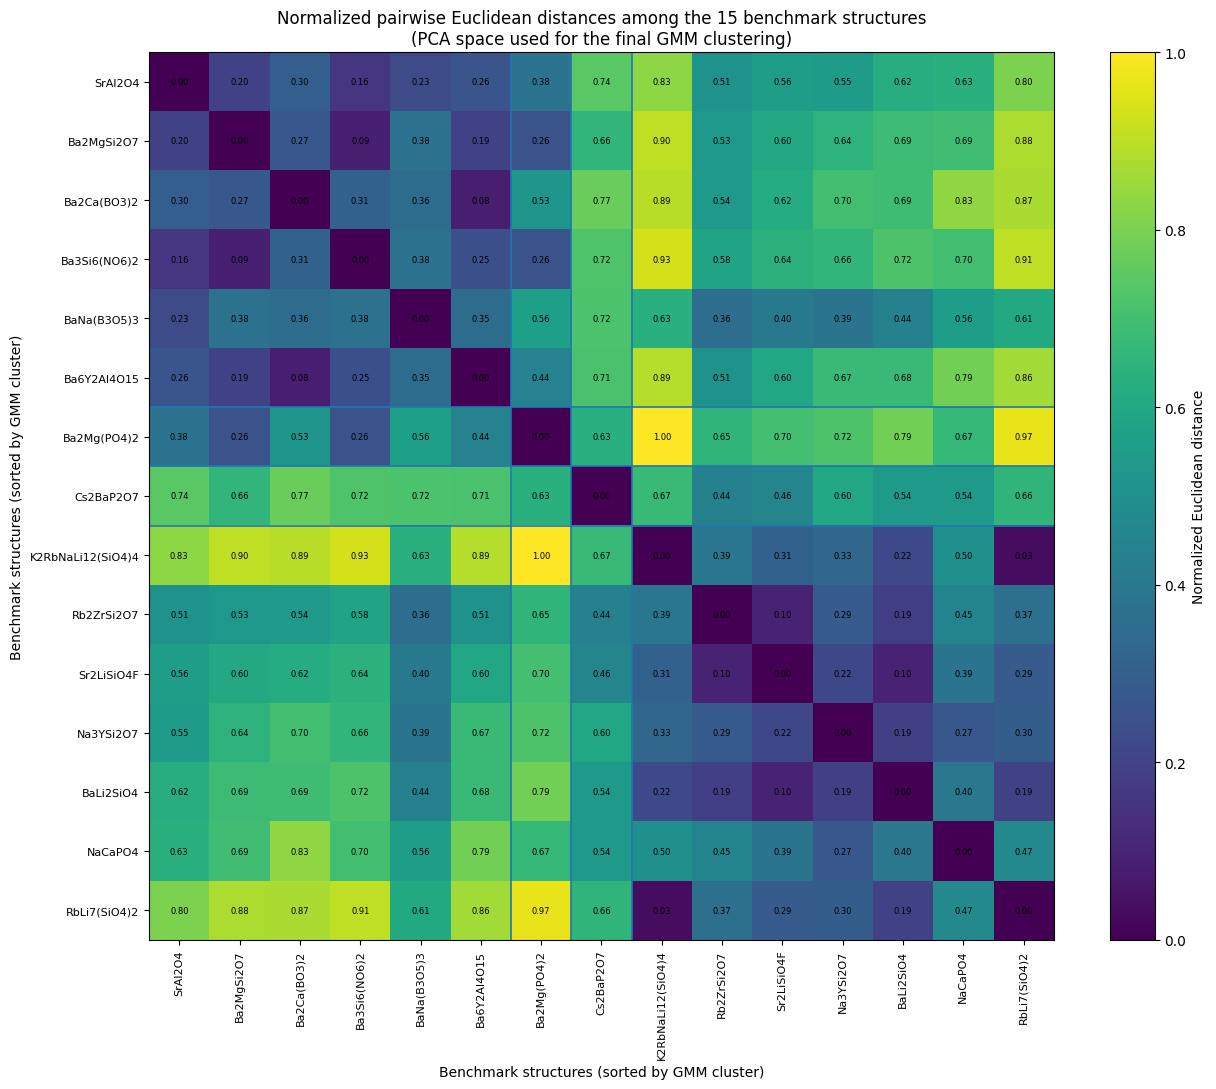


：E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\code\Density-based clustering\DBSCAN\DBSCAN5-deybe\benchmark_distance_output\15_benchmark_normalized_euclidean_distance_heatmap.png

Ten nearest benchmark pairs by pairwise distance:


,Pair_Rank_From_Nearest,Benchmark_A_Number,Benchmark_A_Composition,Cluster_A,Benchmark_B_Number,Benchmark_B_Composition,Cluster_B,Same_Cluster,Euclidean_Distance,Normalized_Euclidean_Distance
0,1,14,K2RbNaLi12(SiO4)4,3,283,RbLi7(SiO4)2,3,True,0.086629,0.034383
1,2,142,Ba2Ca(BO3)2,0,180,Ba6Y2Al4O15,0,True,0.210730,0.083637
2,3,111,Ba2MgSi2O7,0,153,Ba3Si6(NO6)2,0,True,0.223234,0.088600
3,4,15,Rb2ZrSi2O7,3,16,Sr2LiSiO4F,3,True,0.247163,0.098097
4,5,16,Sr2LiSiO4F,3,171,BaLi2SiO4,3,True,0.252411,0.100180
5,6,17,SrAl2O4,0,153,Ba3Si6(NO6)2,0,True,0.397990,0.157960
6,7,15,Rb2ZrSi2O7,3,171,BaLi2SiO4,3,True,0.468804,0.186065
7,8,95,Na3YSi2O7,3,171,BaLi2SiO4,3,True,0.479142,0.190168
8,9,171,BaLi2SiO4,3,283,RbLi7(SiO4)2,3,True,0.482673,0.191570
9,10,111,Ba2MgSi2O7,0,180,Ba6Y2Al4O15,0,True,0.486200,0.192970


In [12]:
# ============================================================


#







#


# ============================================================

from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import pairwise_distances


# ============================================================

# ============================================================

required_vars = ['data', 'reported_structures', 'pca_data', 'labels']

missing_vars = [
    v for v in required_vars
    if v not in globals()
]

if missing_vars:
    raise RuntimeError(
        f" {missing_vars}。"
        "Run the data-loading, benchmark-loading, and final clustering cells first."
    )

if len(reported_structures) != 15:
    raise ValueError(
        f" reported_structures  "
        f"{len(reported_structures)} ，"
        "instead of the expected 15."
    )

if len(pca_data) != len(data) or len(labels) != len(data):
    raise ValueError(
        "new_data / labels do not match the number of rows in data. "
        "Confirm that the final clustering result is being used."
    )


# ============================================================

# ============================================================

number_series = pd.to_numeric(
    data['number'],
    errors='coerce'
)

benchmark_row_indices = []

for num in reported_structures:

    hit = np.flatnonzero(
        number_series.to_numpy() == int(num)
    )

    if len(hit) == 0:
        raise ValueError(
            f" data['number']  "
            f"benchmark number={num}"
        )

    if len(hit) > 1:
        raise ValueError(
            f"benchmark number={num} "
            f" data  {len(hit)} ，"
            "so it cannot be uniquely located."
        )

    benchmark_row_indices.append(
        int(hit[0])
    )



benchmark_pca = np.asarray(pca_data)[
    benchmark_row_indices, :
]

benchmark_clusters = np.asarray(labels)[
    benchmark_row_indices
]

print(
    f" benchmark PCA ："
    f"{benchmark_pca.shape[1]}"
)

print(
    f"Benchmark ："
    f"{benchmark_pca.shape[0]}"
)


# ============================================================

# ============================================================

composition_map = {}

try:

    benchmark_meta = pd.read_excel(file_path)

    if (
        'number' in benchmark_meta.columns
        and 'composition' in benchmark_meta.columns
    ):

        tmp = benchmark_meta[
            ['number', 'composition']
        ].copy()

        tmp['number'] = pd.to_numeric(
            tmp['number'],
            errors='coerce'
        )

        tmp = (
            tmp
            .dropna(subset=['number'])
            .drop_duplicates('number')
        )

        composition_map = {
            int(row['number']): str(row['composition'])
            for _, row in tmp.iterrows()
            if not pd.isna(row['composition'])
        }

except Exception as e:

    print(
        "Note: composition information could not be read. "
        f" number 。：{e}"
    )


benchmark_compositions = [
    composition_map.get(
        int(n),
        f"No.{int(n)}"
    )
    for n in reported_structures
]


benchmark_labels = [
    f"{int(n)} | {c}"
    for n, c in zip(
        reported_structures,
        benchmark_compositions
    )
]


# ============================================================

# ============================================================

distance_matrix = pairwise_distances(
    benchmark_pca,
    metric='euclidean'
)


np.fill_diagonal(
    distance_matrix,
    0.0
)


distance_df = pd.DataFrame(
    distance_matrix,
    index=benchmark_labels,
    columns=benchmark_labels
)

distance_df.index.name = 'Benchmark'


# ============================================================

# ============================================================



#
# normalized_distance = distance / max(distance)
#



max_distance = np.max(distance_matrix)

if max_distance <= 0:
    raise ValueError(
        "The maximum Euclidean distance is zero, so normalization cannot be performed."
    )


normalized_distance_matrix = (
    distance_matrix / max_distance
)

np.fill_diagonal(
    normalized_distance_matrix,
    0.0
)


normalized_distance_df = pd.DataFrame(
    normalized_distance_matrix,
    index=benchmark_labels,
    columns=benchmark_labels
)

normalized_distance_df.index.name = 'Benchmark'


print(
    f"\n："
    f"{max_distance:.6f}"
)

print(
    "Normalized distance range: "
    f"{normalized_distance_matrix.min():.4f} "
    "– "
    f"{normalized_distance_matrix.max():.4f}"
)


# ============================================================

# ============================================================

pair_records = []

for i, j in combinations(
    range(len(reported_structures)),
    2
):

    pair_records.append({

        'Benchmark_A_Number':
            int(reported_structures[i]),

        'Benchmark_A_Composition':
            benchmark_compositions[i],

        'Cluster_A':
            int(benchmark_clusters[i]),

        'Benchmark_B_Number':
            int(reported_structures[j]),

        'Benchmark_B_Composition':
            benchmark_compositions[j],

        'Cluster_B':
            int(benchmark_clusters[j]),

        'Same_Cluster':
            bool(
                benchmark_clusters[i]
                == benchmark_clusters[j]
            ),


        'Euclidean_Distance':
            float(
                distance_matrix[i, j]
            ),


        'Normalized_Euclidean_Distance':
            float(
                normalized_distance_matrix[i, j]
            ),
    })


pairwise_df = pd.DataFrame(
    pair_records
)



pairwise_df = (
    pairwise_df
    .sort_values(
        'Euclidean_Distance',
        ascending=True
    )
    .reset_index(drop=True)
)


pairwise_df.insert(
    0,
    'Pair_Rank_From_Nearest',
    np.arange(
        1,
        len(pairwise_df) + 1
    )
)


# ============================================================

# ============================================================

pc_cols = [
    f'PC{i+1}'
    for i in range(
        benchmark_pca.shape[1]
    )
]


benchmark_info_df = pd.DataFrame(
    benchmark_pca,
    columns=pc_cols
)


benchmark_info_df.insert(
    0,
    'Cluster',
    benchmark_clusters.astype(int)
)


benchmark_info_df.insert(
    0,
    'Composition',
    benchmark_compositions
)


benchmark_info_df.insert(
    0,
    'Number',
    [
        int(x)
        for x in reported_structures
    ]
)


# ============================================================

# ============================================================

sort_order = np.argsort(
    benchmark_clusters,
    kind='stable'
)


sorted_labels = [
    benchmark_labels[k]
    for k in sort_order
]


# -------------------------

# -------------------------

sorted_distance_df = pd.DataFrame(

    distance_matrix[
        np.ix_(
            sort_order,
            sort_order
        )
    ],

    index=sorted_labels,
    columns=sorted_labels
)

sorted_distance_df.index.name = 'Benchmark'


# -------------------------

# -------------------------

sorted_normalized_distance_df = pd.DataFrame(

    normalized_distance_matrix[
        np.ix_(
            sort_order,
            sort_order
        )
    ],

    index=sorted_labels,
    columns=sorted_labels
)

sorted_normalized_distance_df.index.name = 'Benchmark'


# ============================================================

# ============================================================

same_cluster_raw = pairwise_df.loc[
    pairwise_df['Same_Cluster'],
    'Euclidean_Distance'
]

diff_cluster_raw = pairwise_df.loc[
    ~pairwise_df['Same_Cluster'],
    'Euclidean_Distance'
]


same_cluster_norm = pairwise_df.loc[
    pairwise_df['Same_Cluster'],
    'Normalized_Euclidean_Distance'
]

diff_cluster_norm = pairwise_df.loc[
    ~pairwise_df['Same_Cluster'],
    'Normalized_Euclidean_Distance'
]


summary_df = pd.DataFrame({

    'Metric': [

        'Number_of_benchmarks',

        'Number_of_unique_pairs',

        'Maximum_raw_distance',

        'Mean_raw_distance_all_pairs',

        'Median_raw_distance_all_pairs',

        'Mean_raw_distance_same_cluster',

        'Median_raw_distance_same_cluster',

        'Mean_raw_distance_different_cluster',

        'Median_raw_distance_different_cluster',

        'Mean_normalized_distance_all_pairs',

        'Median_normalized_distance_all_pairs',

        'Mean_normalized_distance_same_cluster',

        'Median_normalized_distance_same_cluster',

        'Mean_normalized_distance_different_cluster',

        'Median_normalized_distance_different_cluster',
    ],


    'Value': [

        len(reported_structures),

        len(pairwise_df),

        max_distance,

        pairwise_df[
            'Euclidean_Distance'
        ].mean(),

        pairwise_df[
            'Euclidean_Distance'
        ].median(),

        same_cluster_raw.mean()
        if len(same_cluster_raw)
        else np.nan,

        same_cluster_raw.median()
        if len(same_cluster_raw)
        else np.nan,

        diff_cluster_raw.mean()
        if len(diff_cluster_raw)
        else np.nan,

        diff_cluster_raw.median()
        if len(diff_cluster_raw)
        else np.nan,

        pairwise_df[
            'Normalized_Euclidean_Distance'
        ].mean(),

        pairwise_df[
            'Normalized_Euclidean_Distance'
        ].median(),

        same_cluster_norm.mean()
        if len(same_cluster_norm)
        else np.nan,

        same_cluster_norm.median()
        if len(same_cluster_norm)
        else np.nan,

        diff_cluster_norm.mean()
        if len(diff_cluster_norm)
        else np.nan,

        diff_cluster_norm.median()
        if len(diff_cluster_norm)
        else np.nan,
    ]
})


# ============================================================

# ============================================================

output_dir = (
    Path.cwd()
    / 'benchmark_distance_output'
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)


excel_path = (
    output_dir
    / '15_benchmark_pairwise_euclidean_distance_normalized.xlsx'
)


with pd.ExcelWriter(
    excel_path,
    engine='openpyxl'
) as writer:


    distance_df.to_excel(
        writer,
        sheet_name='Distance_Matrix'
    )


    normalized_distance_df.to_excel(
        writer,
        sheet_name='Normalized_Distance_Matrix'
    )


    pairwise_df.to_excel(
        writer,
        sheet_name='Pairwise_105',
        index=False
    )


    benchmark_info_df.to_excel(
        writer,
        sheet_name='Benchmark_PCA_Cluster',
        index=False
    )


    sorted_distance_df.to_excel(
        writer,
        sheet_name='Raw_Matrix_Sorted'
    )


    sorted_normalized_distance_df.to_excel(
        writer,
        sheet_name='Normalized_Matrix_Sorted'
    )


    summary_df.to_excel(
        writer,
        sheet_name='Summary',
        index=False
    )


print(
    f"\nExcel ："
    f"{excel_path.resolve()}"
)


# ============================================================

# ============================================================

heatmap_matrix = (
    normalized_distance_matrix[
        np.ix_(
            sort_order,
            sort_order
        )
    ]
)


heatmap_labels = [
    benchmark_compositions[k]
    for k in sort_order
]


heatmap_clusters = (
    benchmark_clusters[
        sort_order
    ]
)


fig, ax = plt.subplots(
    figsize=(13, 11)
)



im = ax.imshow(
    heatmap_matrix,
    aspect='auto',
    vmin=0,
    vmax=1
)


# -------------------------

# -------------------------

ax.set_xticks(
    np.arange(
        len(heatmap_labels)
    )
)

ax.set_yticks(
    np.arange(
        len(heatmap_labels)
    )
)


ax.set_xticklabels(
    heatmap_labels,
    rotation=90,
    fontsize=8
)

ax.set_yticklabels(
    heatmap_labels,
    fontsize=8
)


ax.set_xlabel(
    'Benchmark structures '
    '(sorted by GMM cluster)'
)

ax.set_ylabel(
    'Benchmark structures '
    '(sorted by GMM cluster)'
)


ax.set_title(
    'Normalized pairwise Euclidean distances '
    'among the 15 benchmark structures\n'
    '(PCA space used for the final GMM clustering)'
)


# -------------------------
# Colorbar
# -------------------------

cbar = fig.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    'Normalized Euclidean distance'
)



cbar.set_ticks(
    np.linspace(
        0,
        1,
        6
    )
)


# ============================================================

# ============================================================

for r in range(
    len(heatmap_labels)
):

    for c in range(
        len(heatmap_labels)
    ):

        value = heatmap_matrix[r, c]

        ax.text(
            c,
            r,
            f"{value:.2f}",
            ha='center',
            va='center',
            fontsize=6
        )


# ============================================================

# ============================================================

cluster_boundaries = np.where(
    np.diff(
        heatmap_clusters
    ) != 0
)[0]


for b in cluster_boundaries:

    ax.axhline(
        b + 0.5,
        linewidth=1.2
    )

    ax.axvline(
        b + 0.5,
        linewidth=1.2
    )


# ============================================================

# ============================================================

fig.tight_layout()


figure_path = (
    output_dir
    / '15_benchmark_normalized_euclidean_distance_heatmap.png'
)


fig.savefig(
    figure_path,
    dpi=600,
    bbox_inches='tight'
)


plt.show()


print(
    f"\n："
    f"{figure_path.resolve()}"
)


# ============================================================

# ============================================================

print(
    "\nTen nearest benchmark pairs by pairwise distance:"
)


display(
    pairwise_df.head(10)
)

：E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\code\Density-based clustering\DBSCAN\DBSCAN5-deybe\FWHM_pair_distance_figures

Excel loaded successfully.
：105

Current Excel columns:
Pair_Rank_From_Nearest
Benchmark_A_Number
Benchmark_A_Composition
Cluster_A
Benchmark_B_Number
Benchmark_B_Composition
Cluster_B
Same_Cluster
Euclidean_Distance
Normalized_Euclidean_Distance
Debye_Temperature_Difference_K

pair：105

Spearman correlation
Spearman rho = 0.3574
p-value = 0.0002

LOWESS smoothing: statsmodels LOWESS


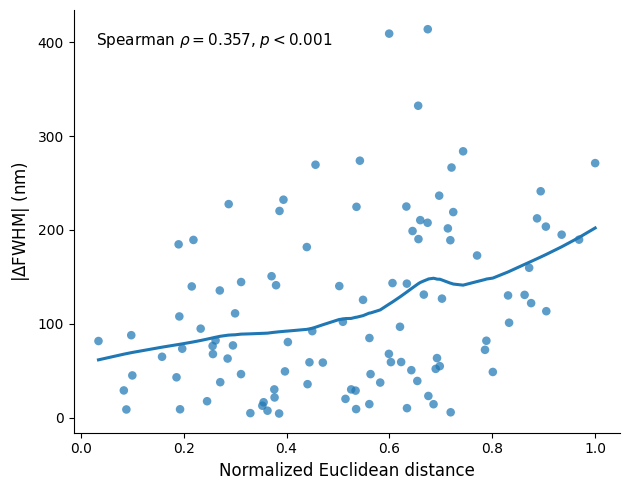


Figure 1 SVG：E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\code\Density-based clustering\DBSCAN\DBSCAN5-deybe\FWHM_pair_distance_figures\FWHM_distance_scatter_LOWESS.svg
Figure 1 PNG：E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\code\Density-based clustering\DBSCAN\DBSCAN5-deybe\FWHM_pair_distance_figures\FWHM_distance_scatter_LOWESS.png

Distance quartile statistics

Q1:
n = 27
Distance range = 0.0344 – 0.3296
Mean |ΔFWHM| = 83.30 nm
Median |ΔFWHM| = 76.30 nm

Q2:
n = 26
Distance range = 0.3529 – 0.5426
Mean |ΔFWHM| = 95.81 nm
Median |ΔFWHM| = 58.75 nm

Q3:
n = 26
Distance range = 0.5487 – 0.6900
Mean |ΔFWHM| = 130.21 nm
Median |ΔFWHM| = 90.80 nm

Q4:
n = 26
Distance range = 0.6925 – 1.0000
Mean |ΔFWHM| = 157.45 nm
Median |ΔFWHM| = 166.25 nm


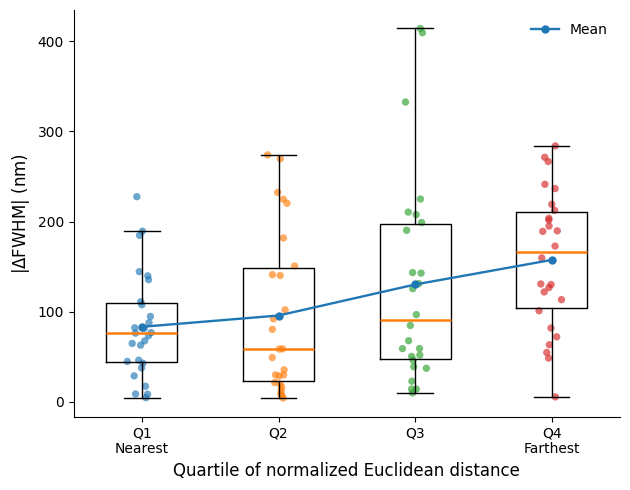


Figure 2 SVG：E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\code\Density-based clustering\DBSCAN\DBSCAN5-deybe\FWHM_pair_distance_figures\FWHM_distance_quartile_boxplot.svg
Figure 2 PNG：E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\code\Density-based clustering\DBSCAN\DBSCAN5-deybe\FWHM_pair_distance_figures\FWHM_distance_quartile_boxplot.png

Final summary
Number of pairs = 105
Spearman rho = 0.3574
Spearman p = 0.0002
Q1: mean |ΔFWHM| = 83.30 nm, median = 76.30 nm
Q2: mean |ΔFWHM| = 95.81 nm, median = 58.75 nm
Q3: mean |ΔFWHM| = 130.21 nm, median = 90.80 nm
Q4: mean |ΔFWHM| = 157.45 nm, median = 166.25 nm


In [14]:
# ============================================================
# Pairwise Euclidean distance vs FWHM difference
#




#    Figure 1: Normalized Euclidean distance vs |ΔFWHM|
#              Scatter + LOWESS smoothing
#    Figure 2: Distance quartile vs |ΔFWHM|
#              Boxplot + raw points + mean trend

#

#   Normalized_Euclidean_Distance
#   Debye_Temperature_Difference_K
# ============================================================


# ============================================================

# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr


# ============================================================

# ============================================================


input_excel = Path(
    r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\code\Density-based clustering\DBSCAN\DBSCAN5-deybe\benchmark_distance_output\105Pair_deybe_diff.xlsx"
)





# ============================================================

# ============================================================

figure_dir = Path.cwd() / "FWHM_pair_distance_figures"

figure_dir.mkdir(
    parents=True,
    exist_ok=True
)

print(
    f"：{figure_dir.resolve()}"
)


# ============================================================

# ============================================================

df = pd.read_excel(
    input_excel,
    sheet_name="Pairwise_105"
)

print("\nExcel loaded successfully.")
print(f"：{len(df)}")

print("\nCurrent Excel columns:")
for col in df.columns:
    print(col)


# ============================================================

# ============================================================

required_columns = [
    "Normalized_Euclidean_Distance",
    "Debye_Temperature_Difference_K"
]

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing_columns:

    raise ValueError(
        f"Excel：{missing_columns}\n"
        "Check whether the Excel column names exactly match those required by the code."
    )


# ============================================================

# ============================================================

x = pd.to_numeric(
    df["Normalized_Euclidean_Distance"],
    errors="coerce"
).to_numpy()

y = pd.to_numeric(
    df["Debye_Temperature_Difference_K"],
    errors="coerce"
).to_numpy()



valid_mask = (
    np.isfinite(x)
    &
    np.isfinite(y)
)

x = x[valid_mask]
y = y[valid_mask]


print(
    f"\npair：{len(x)}"
)


# ============================================================

# ============================================================

rho, p_value = spearmanr(
    x,
    y
)

print("\n==============================")
print("Spearman correlation")
print("==============================")

print(
    f"Spearman rho = {rho:.4f}"
)

print(
    f"p-value = {p_value:.4f}"
)


# ============================================================

# ============================================================





use_lowess = False

try:

    from statsmodels.nonparametric.smoothers_lowess import lowess

    lowess_result = lowess(
        endog=y,
        exog=x,


        frac=0.45,


        it=0,

        return_sorted=True
    )

    smooth_x = lowess_result[:, 0]
    smooth_y = lowess_result[:, 1]

    use_lowess = True

    print(
        "\nLOWESS smoothing: statsmodels LOWESS"
    )

except ImportError:

    print(
        "\nstatsmodels was not detected."
        "A moving-window median will be used automatically for smoothing."
    )

    order = np.argsort(x)

    xs = x[order]
    ys = y[order]


    window = max(
        9,
        len(xs) // 10
    )

    smooth_x = []
    smooth_y = []

    for i in range(
        len(xs)
    ):

        left = max(
            0,
            i - window // 2
        )

        right = min(
            len(xs),
            i + window // 2 + 1
        )

        smooth_x.append(
            xs[i]
        )

        smooth_y.append(
            np.median(
                ys[left:right]
            )
        )

    smooth_x = np.asarray(
        smooth_x
    )

    smooth_y = np.asarray(
        smooth_y
    )


# ============================================================
# 8. Figure 1
# Scatter + LOWESS
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.4, 5.0)
)


# -------------------------

# -------------------------

ax.scatter(
    x,
    y,

    s=38,

    alpha=0.72,

    edgecolors="none"
)


# -------------------------
# LOWESS / smoothing curve
# -------------------------

ax.plot(
    smooth_x,
    smooth_y,

    linewidth=2.2
)


# -------------------------

# -------------------------

ax.set_xlabel(
    "Normalized Euclidean distance",
    fontsize=12
)

ax.set_ylabel(
    r"$|\Delta \mathrm{FWHM}|$ (nm)",
    fontsize=12
)


ax.tick_params(
    axis="both",
    labelsize=10
)


# -------------------------

# -------------------------

if p_value < 0.001:

    p_text = r"$p<0.001$"

else:

    p_text = fr"$p={p_value:.3f}$"


ax.text(
    0.04,
    0.95,

    fr"Spearman $\rho={rho:.3f}$, {p_text}",

    transform=ax.transAxes,

    fontsize=11,

    va="top"
)


# -------------------------

# -------------------------

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)


fig.tight_layout()


# ============================================================

# ============================================================

svg_path_1 = (
    figure_dir
    /
    "FWHM_distance_scatter_LOWESS.svg"
)

png_path_1 = (
    figure_dir
    /
    "FWHM_distance_scatter_LOWESS.png"
)


fig.savefig(
    svg_path_1,

    format="svg",

    bbox_inches="tight"
)


fig.savefig(
    png_path_1,

    dpi=600,

    bbox_inches="tight"
)


plt.show()


print(
    f"\nFigure 1 SVG：{svg_path_1.resolve()}"
)

print(
    f"Figure 1 PNG：{png_path_1.resolve()}"
)


# ============================================================

# ============================================================


sort_idx = np.argsort(x)

n_samples = len(x)





rank_group = np.zeros(
    n_samples,
    dtype=int
)


for rank, original_index in enumerate(
    sort_idx
):

    group = int(
        rank * 4 / n_samples
    )

    group = min(
        group,
        3
    )

    rank_group[
        original_index
    ] = group


# Q1-Q4
groups = [

    y[
        rank_group == i
    ]

    for i in range(
        4
    )
]



distance_groups = [

    x[
        rank_group == i
    ]

    for i in range(
        4
    )
]


# ============================================================

# ============================================================

group_means = [

    np.mean(
        values
    )

    for values in groups
]


group_medians = [

    np.median(
        values
    )

    for values in groups
]


print(
    "\n=========================================="
)

print(
    "Distance quartile statistics"
)

print(
    "=========================================="
)


for i in range(
    4
):

    values = groups[i]

    distances = distance_groups[i]

    print(
        f"\nQ{i+1}:"
    )

    print(
        f"n = {len(values)}"
    )

    print(
        "Distance range = "
        f"{distances.min():.4f} – "
        f"{distances.max():.4f}"
    )

    print(
        "Mean |ΔFWHM| = "
        f"{np.mean(values):.2f} nm"
    )

    print(
        "Median |ΔFWHM| = "
        f"{np.median(values):.2f} nm"
    )


# ============================================================
# 12. Figure 2
# Distance quartile boxplot
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.4, 5.0)
)


# -------------------------
# Boxplot
# -------------------------

boxplot_result = ax.boxplot(
    groups,

    positions=[
        1,
        2,
        3,
        4
    ],

    widths=0.52,

    showfliers=False,

    patch_artist=False,

    medianprops={
        "linewidth": 1.8
    }
)


# ============================================================

# ============================================================




rng = np.random.default_rng(
    42
)


for position, values in enumerate(
    groups,
    start=1
):

    jitter = rng.normal(
        loc=0,
        scale=0.055,
        size=len(values)
    )

    x_points = (
        np.full(
            len(values),
            position,
            dtype=float
        )
        +
        jitter
    )

    ax.scatter(
        x_points,
        values,

        s=28,

        alpha=0.65,

        edgecolors="none"
    )


# ============================================================

# ============================================================

ax.plot(
    [
        1,
        2,
        3,
        4
    ],

    group_means,

    marker="o",

    markersize=5,

    linewidth=1.7,

    label="Mean"
)


# ============================================================

# ============================================================

ax.set_xticks(
    [
        1,
        2,
        3,
        4
    ]
)


ax.set_xticklabels(
    [
        "Q1\nNearest",
        "Q2",
        "Q3",
        "Q4\nFarthest"
    ],

    fontsize=10
)


ax.set_xlabel(
    "Quartile of normalized Euclidean distance",
    fontsize=12
)


ax.set_ylabel(
    r"$|\Delta \mathrm{FWHM}|$ (nm)",
    fontsize=12
)


ax.tick_params(
    axis="y",
    labelsize=10
)


# -------------------------
# Legend
# -------------------------

ax.legend(
    frameon=False,

    fontsize=10
)


# -------------------------

# -------------------------

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)


fig.tight_layout()


# ============================================================

# ============================================================

svg_path_2 = (
    figure_dir
    /
    "FWHM_distance_quartile_boxplot.svg"
)

png_path_2 = (
    figure_dir
    /
    "FWHM_distance_quartile_boxplot.png"
)


fig.savefig(
    svg_path_2,

    format="svg",

    bbox_inches="tight"
)


fig.savefig(
    png_path_2,

    dpi=600,

    bbox_inches="tight"
)


plt.show()


print(
    f"\nFigure 2 SVG：{svg_path_2.resolve()}"
)

print(
    f"Figure 2 PNG：{png_path_2.resolve()}"
)


# ============================================================

# ============================================================

print(
    "\n=========================================="
)

print(
    "Final summary"
)

print(
    "=========================================="
)


print(
    f"Number of pairs = {len(x)}"
)


print(
    f"Spearman rho = {rho:.4f}"
)


print(
    f"Spearman p = {p_value:.4f}"
)


for i in range(
    4
):

    print(
        f"Q{i+1}: "
        f"mean |ΔFWHM| = "
        f"{group_means[i]:.2f} nm, "
        f"median = "
        f"{group_medians[i]:.2f} nm"
    )